# Modelado · Clusterización de perfiles de paciente
### Proyecto de Aprendizaje Automático · Encuesta de salud del consorcio de atención primaria

**Objetivo.** Encontrar grupos de pacientes con características parecidas para dimensionar y dirigir los programas de prevención. El enunciado pone el listón en la interpretabilidad: *un grupo que no se pueda describir en una frase a un profesional sanitario no le sirve a nadie*.

No hay variable objetivo ni datos retenidos con los que medir el error, así que los grupos se valoran por **estabilidad**, **tamaño útil** e **interpretabilidad**, y las métricas de compacidad son solo una ayuda. El EDA (sección 9) ya avisó de que los datos forman un continuo: los grupos serán una segmentación útil de ese continuo, no islas naturales.

> 🔧 **CLAUDE — REVISAR Y BORRAR ESTA CELDA**
>
> - Notebook nuevo. Usa funciones nuevas de `src/modelado.py` (`kmeans`, `construir_clustering`, `metricas_clustering`, `estabilidad_clustering` y `CONFIG_FINAL["clustering"]`).
> - Cambios en `src/preprocesamiento.py`: `COLS_CLUSTERING` ya no incluye `diabetes` ni `dias_salud_fisica_mala` (sección 2); `con_objetivo_cruzado=True` los vuelve a incluir para la comparación; y `anadir_features` solo calcula cada variable derivada si están sus columnas de origen (antes fallaba con las 10 columnas del clustering porque exigía `ictus`).

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.pipeline import Pipeline

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src"))
import eda_utils as eu
import modelado as md
import preprocesamiento as pp

warnings.filterwarnings("ignore", message=".*valores no reconocidos.*")
eu.configurar_estilo()
LINEA = "clustering"

## 1. Datos y variables

- Se usan los **12 750 pacientes**: no hay nada que predecir ni que reservar para test. La estabilidad se mide entrenando con mitades distintas de los datos.
- **Variables para formar los grupos**: las 10 de salud y hábitos de `pp.COLS_CLUSTERING` (edad, IMC, salud percibida, días de mala salud mental, hipertensión, colesterol, cardiopatía, dificultad para caminar, actividad física y tabaco), imputadas y estandarizadas dentro del pipeline.
- **Variables para describirlos después**: los dos objetivos (`diabetes` y `dias_salud_fisica_mala`) y las sociodemográficas (sexo, educación, ingresos). Así los grupos se forman por estado de salud y no por renta.

In [2]:
crudo = pp.cargar_datos()
COLUMNAS = pp.columnas_crudas(LINEA)
X = crudo[COLUMNAS]
limpio = pp.preparar(crudo)
print(f"{len(X):,} pacientes · {len(COLUMNAS)} variables para agrupar:", COLUMNAS)
assert not set(COLUMNAS) & set(pp.COLS_PII + pp.COLS_GESTION + [pp.COL_ID, pp.TARGET_CLASIF, pp.TARGET_REGR])

12,750 pacientes · 10 variables para agrupar: ['imc', 'dias_salud_mental_mala', 'grupo_edad', 'salud_general', 'presion_alta', 'colesterol_alto', 'enfermedad_cardiaca', 'dificultad_caminar', 'actividad_fisica', 'fumador']


## 2. ¿Se incluyen los objetivos al formar los grupos?

En el PC1 la lista de clustering incluía `diabetes` y `dias_salud_fisica_mala`. Se compara con K-means agrupar **con** y **sin** ellos. La estabilidad es el ARI medio entre los grupos que salen al entrenar con dos mitades distintas de los datos (1 = mismos grupos; 0 = nada en común).

In [3]:
def con_objetivos(k, semilla):
    return Pipeline([("pre", pp.construir_preprocesador(LINEA, con_objetivo_cruzado=True)), ("modelo", md.kmeans(k, semilla))])


def sin_objetivos(k, semilla):
    return md.construir_clustering(md.kmeans(k, semilla))


X_con = crudo[pp.columnas_crudas(LINEA, con_objetivo_cruzado=True)]
filas = []
for nombre, construir, datos in [("con objetivos (12 var.)", con_objetivos, X_con), ("sin objetivos (10 var.)", sin_objetivos, X)]:
    for k in range(3, 7):
        modelo = construir(k, pp.SEMILLA).fit(datos)
        Xt = modelo.named_steps["pre"].transform(datos).to_numpy()
        filas.append({"variables": nombre, "k": k, **md.metricas_clustering(Xt, modelo.predict(datos)),
                      "Estabilidad (ARI)": md.estabilidad_clustering(construir, datos, k)})
comparacion = pd.DataFrame(filas).set_index(["variables", "k"])
comparacion.style.format("{:.3f}")

**Hallazgos**

- **Sin los objetivos, los grupos están mejor separados y son igual de estables.** Con 5 grupos, la silueta sube de 0,143 a 0,185 y el Davies-Bouldin baja de 2,07 a 1,76, con una estabilidad parecida (0,85 frente a 0,86). Con 4 grupos son incluso más estables sin ellos (0,97 frente a 0,93).
- **Decisión: los grupos se forman sin `diabetes` ni `dias_salud_fisica_mala`** (decisión #25), por tres motivos:
  1. Las métricas no empeoran y con 5 grupos mejoran.
  2. Quedan como **validación externa**: si los grupos, formados sin ellas, las separan, es que reflejan diferencias clínicas reales (sección 4).
  3. **Robustez de la API**: el servicio exige todas las columnas que usa el modelo. Si una petición de clusterización llegara sin los objetivos, la línea entera devolvería un error 422.

## 3. Algoritmo y número de grupos

Con las 10 variables se comparan dos algoritmos que pueden asignar un grupo a un paciente nuevo (requisito de la API):

- **K-means**: grupos esféricos alrededor de un centro; cada paciente va al centro más cercano.
- **Mezcla de gaussianas (GMM)**: grupos elípticos con probabilidad de pertenencia.

Se prueba de 2 a 7 grupos. Además de la estabilidad: silueta (más alta, mejor separados), Davies-Bouldin (más bajo, mejor) y el tamaño del grupo más pequeño (un programa de prevención para el 2 % de la población no es práctico).

In [4]:
def gmm(k, semilla):
    return md.construir_clustering(GaussianMixture(k, covariance_type="full", n_init=2, random_state=semilla))


Xt = md.construir_clustering(md.kmeans(2)).fit(X).named_steps["pre"].transform(X).to_numpy()
filas = []
for nombre, construir in [("K-means", sin_objetivos), ("GMM", gmm)]:
    for k in range(2, 8):
        modelo = construir(k, pp.SEMILLA).fit(X)
        filas.append({"algoritmo": nombre, "k": k, **md.metricas_clustering(Xt, modelo.predict(X)),
                      "Estabilidad (ARI)": md.estabilidad_clustering(construir, X, k)})
rejilla = pd.DataFrame(filas)
rejilla.set_index(["algoritmo", "k"]).style.format("{:.3f}")

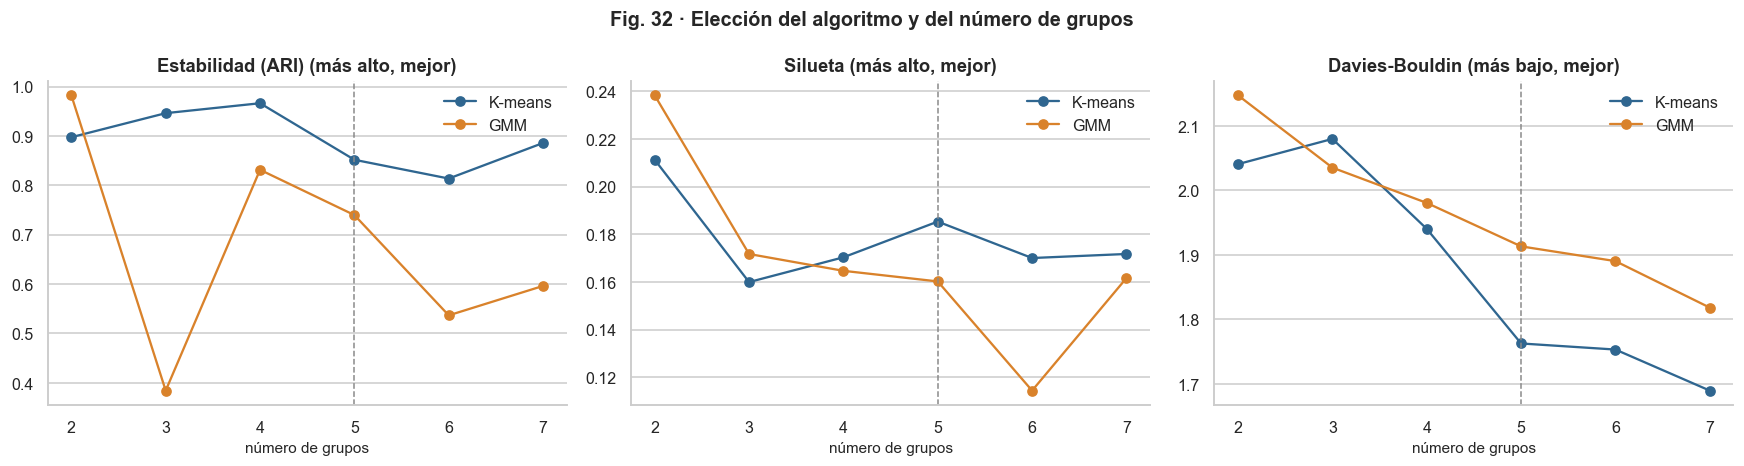

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
for algoritmo, color in [("K-means", eu.AZUL), ("GMM", eu.NARANJA)]:
    r = rejilla[rejilla["algoritmo"] == algoritmo]
    for ax, metrica in zip(axes, ["Estabilidad (ARI)", "Silueta", "Davies-Bouldin"]):
        ax.plot(r["k"], r[metrica], "o-", color=color, label=algoritmo)
for ax, (metrica, mejor) in zip(axes, [("Estabilidad (ARI)", "más alto, mejor"), ("Silueta", "más alto, mejor"),
                                       ("Davies-Bouldin", "más bajo, mejor")]):
    ax.axvline(md.CONFIG_FINAL[LINEA]["k"], color=eu.GRIS, ls="--", lw=1)
    ax.set(title=f"{metrica} ({mejor})", xlabel="número de grupos")
    ax.legend()
fig.suptitle("Fig. 32 · Elección del algoritmo y del número de grupos")
fig.tight_layout()
eu.guardar_figura(fig, "fig32_eleccion_clustering")
plt.show()

**Hallazgos**

- **Las siluetas son bajas en todos los casos (0,16 a 0,24).** Confirma lo que vio el EDA: los pacientes forman un continuo, no grupos separados. Por eso pesan más la estabilidad y la interpretabilidad.
- **GMM es inestable a partir de 3 grupos** (ARI de 0,38 a 0,83): con tantas variables binarias, las gaussianas encuentran soluciones distintas en cada mitad de los datos. **Se descarta.**
- **K-means es estable de 2 a 7 grupos** (ARI de 0,81 a 0,97). La duda está entre 4 y 5:

| | 4 grupos | 5 grupos |
|---|---|---|
| Estabilidad (ARI) | **0,97** | 0,85 |
| Silueta | 0,170 | **0,185** |
| Davies-Bouldin | 1,94 | **1,76** |
| Grupo más pequeño | 12,7 % | 7,7 % |

- **Decisión: K-means con 5 grupos** (decisión #26). Separa mejor, sigue siendo estable (dos mitades distintas de los datos dan casi los mismos grupos) y el quinto grupo es un perfil con sentido clínico propio: pacientes con malestar psicológico (sección 4). Con 6 grupos baja la estabilidad (0,81) y no mejora la silueta.

In [6]:
K = md.CONFIG_FINAL[LINEA]["k"]
modelo_final = md.construir_final(LINEA).fit(X)
grupos = modelo_final.predict(X)
print("CONFIG_FINAL['clustering'] =", md.CONFIG_FINAL[LINEA])
print("Pacientes por grupo:", dict(zip(*np.unique(grupos, return_counts=True))))

CONFIG_FINAL['clustering'] = {'estimador': 'kmeans', 'k': 5}
Pacientes por grupo: {np.int32(0): np.int64(1581), np.int32(1): np.int64(4954), np.int32(2): np.int64(3798), np.int32(3): np.int64(979), np.int32(4): np.int64(1438)}


## 4. Perfiles: ¿quién hay en cada grupo?

Media de cada variable por grupo, en su escala original. Las dos columnas de la derecha del bloque de salud (`diabetes` y días de mala salud física) **no se usaron para formar los grupos**: sirven de validación externa. Si los grupos tienen sentido clínico, deberían separarlas.

In [7]:
d = limpio.assign(grupo=grupos)
perfil = d.groupby("grupo").agg(**{
    "% pacientes": ("imc", "size"),
    "Edad (1-13)": ("grupo_edad", "mean"),
    "Salud (1 exc.-5 mala)": ("salud_general", "mean"),
    "IMC": ("imc", "mean"),
    "Días salud mental": ("dias_salud_mental_mala", "mean"),
    "% hipertensión": ("presion_alta", "mean"),
    "% colesterol": ("colesterol_alto", "mean"),
    "% cardiopatía": ("enfermedad_cardiaca", "mean"),
    "% dif. caminar": ("dificultad_caminar", "mean"),
    "% activos": ("actividad_fisica", "mean"),
    "% fumadores": ("fumador", "mean"),
    "% diabetes (*)": ("diabetes", "mean"),
    "Días salud física (*)": ("dias_salud_fisica_mala", "mean"),
    "% hombres": ("es_hombre", "mean"),
    "Ingresos (1-8)": ("nivel_ingresos", "mean"),
    "Educación (1-6)": ("nivel_educativo", "mean"),
})
perfil["% pacientes"] = perfil["% pacientes"] / len(d)
global_ = pd.Series({c: perfil[c].mul(perfil["% pacientes"]).sum() for c in perfil.columns}, name="Total")
global_["% pacientes"] = 1.0
perfil_tabla = pd.concat([perfil, global_.to_frame().T])
porcentajes = [c for c in perfil_tabla.columns if c.startswith("%")]
print("(*) No se usan para formar los grupos")
perfil_tabla.style.format("{:.2f}").format("{:.0%}", subset=porcentajes)

(*) No se usan para formar los grupos


,% pacientes,Edad (1-13),Salud (1 exc.-5 mala),IMC,Días salud mental,% hipertensión,% colesterol,% cardiopatía,% dif. caminar,% activos,% fumadores,% diabetes (*),Días salud física (*),% hombres,Ingresos (1-8),Educación (1-6)
0,12%,9.75,3.45,32.55,2.01,70%,59%,0%,99%,50%,56%,55%,11.09,35%,4.66,4.59
1,39%,6.67,2.02,26.72,1.31,3%,22%,0%,1%,86%,34%,10%,1.51,45%,6.62,5.23
2,30%,9.45,2.65,29.71,0.94,89%,64%,0%,0%,74%,48%,39%,2.79,50%,6.04,4.97
3,8%,7.72,3.82,32.06,27.20,65%,63%,19%,53%,53%,61%,51%,16.31,33%,4.49,4.64
4,11%,10.30,3.46,30.10,2.03,79%,75%,100%,44%,61%,61%,60%,8.28,57%,5.04,4.71
Total,100%,8.37,2.69,29.12,3.35,50%,48%,13%,22%,73%,46%,33%,4.98,46%,5.86,4.97


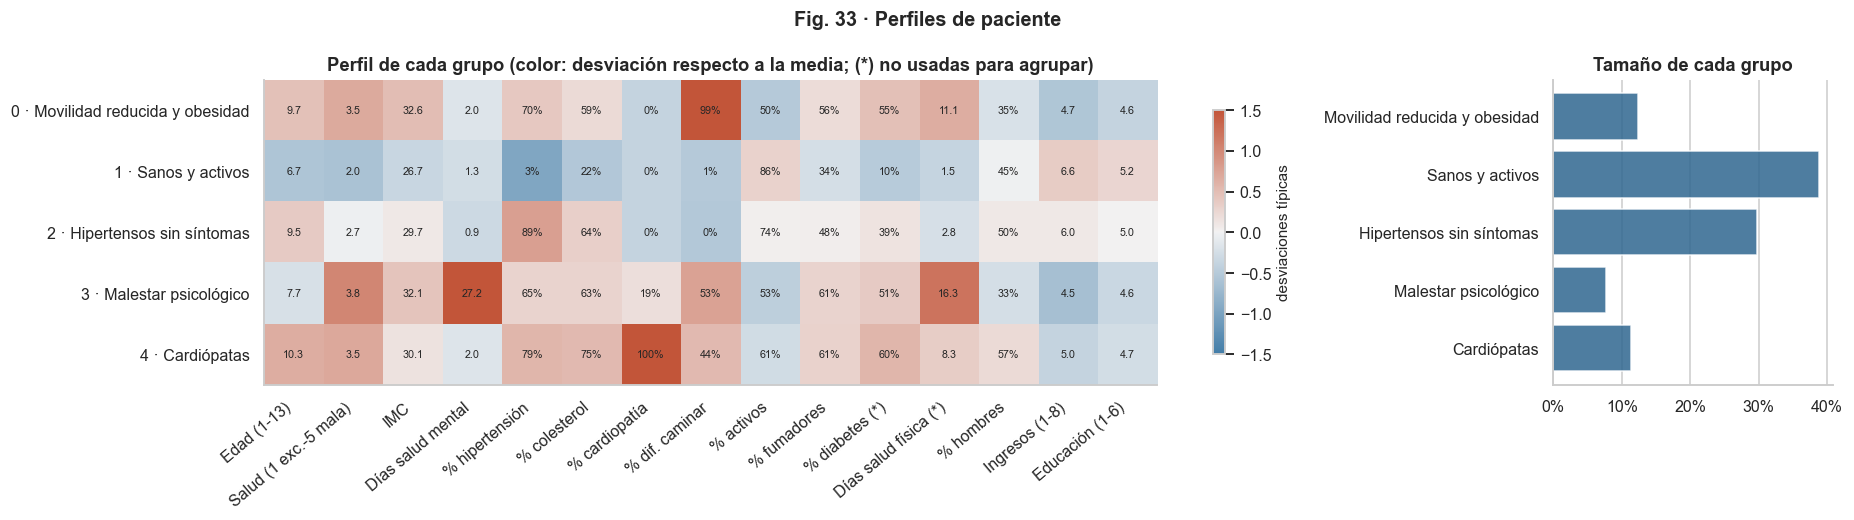

In [8]:
NOMBRES = {
    0: "Movilidad reducida y obesidad",
    1: "Sanos y activos",
    2: "Hipertensos sin síntomas",
    3: "Malestar psicológico",
    4: "Cardiópatas",
}
assert perfil.loc[1, "% hipertensión"] < 0.1 and perfil.loc[1, "% pacientes"] > 0.3
assert perfil.loc[0, "% dif. caminar"] > 0.9
assert perfil.loc[2, "% hipertensión"] > 0.8 and perfil.loc[2, "% dif. caminar"] < 0.05
assert perfil["Días salud mental"].idxmax() == 3
assert perfil.loc[4, "% cardiopatía"] > 0.95

variables = [c for c in perfil.columns if c != "% pacientes"]
z = (perfil[variables] - global_[variables]) / d[[
    "grupo_edad", "salud_general", "imc", "dias_salud_mental_mala", "presion_alta", "colesterol_alto",
    "enfermedad_cardiaca", "dificultad_caminar", "actividad_fisica", "fumador", "diabetes",
    "dias_salud_fisica_mala", "es_hombre", "nivel_ingresos", "nivel_educativo"]].std().to_numpy()
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [4, 1]})
im = ax.imshow(z.to_numpy(), cmap=eu.CMAP_DIVERGENTE, vmin=-1.5, vmax=1.5, aspect="auto")
ax.set_xticks(range(len(variables)), variables, rotation=40, ha="right")
ax.set_yticks(range(K), [f"{g} · {NOMBRES[g]}" for g in range(K)])
for i in range(K):
    for j, v in enumerate(variables):
        valor = perfil.loc[i, v]
        ax.text(j, i, f"{valor:.0%}" if v.startswith("%") else f"{valor:.1f}", ha="center", va="center", fontsize=7)
ax.grid(False)
ax.set_title("Perfil de cada grupo (color: desviación respecto a la media; (*) no usadas para agrupar)")
fig.colorbar(im, ax=ax, shrink=0.8, label="desviaciones típicas")
ax2.barh([NOMBRES[g] for g in range(K)][::-1], perfil["% pacientes"].to_numpy()[::-1], color=eu.AZUL, alpha=0.85)
ax2.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_title("Tamaño de cada grupo")
eu.rejilla_x(ax2)
fig.suptitle("Fig. 33 · Perfiles de paciente")
fig.tight_layout()
eu.guardar_figura(fig, "fig33_perfiles_clustering")
plt.show()

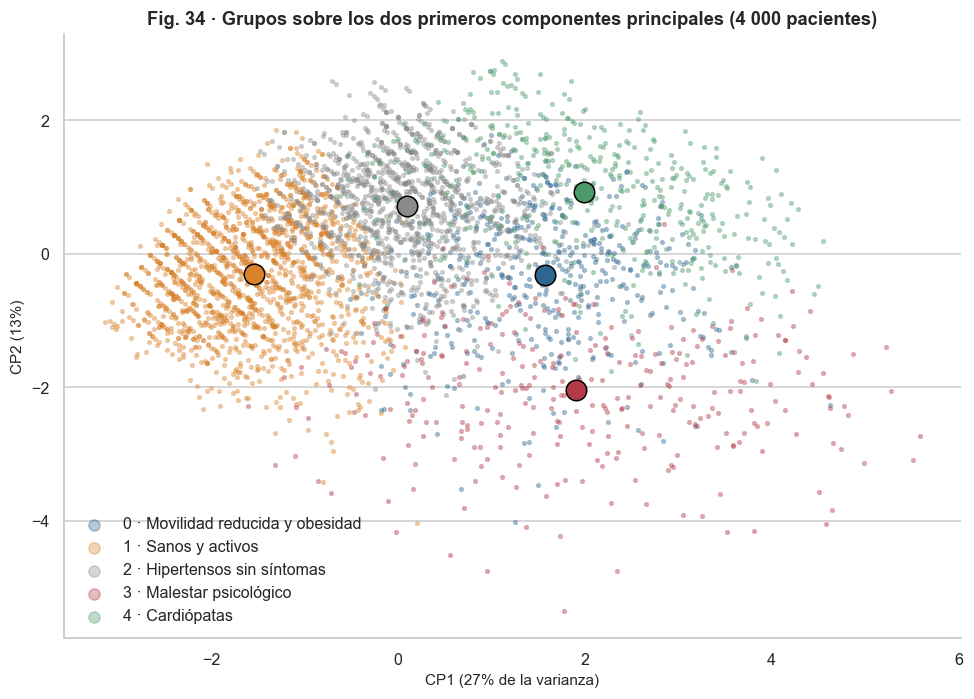

In [9]:
pca = PCA(2, random_state=pp.SEMILLA).fit(Xt)
proy = pca.transform(Xt)
centros = pca.transform(modelo_final.named_steps["modelo"].cluster_centers_)
muestra = np.random.default_rng(pp.SEMILLA).choice(len(X), 4000, replace=False)
colores = [eu.AZUL, eu.NARANJA, eu.GRIS, eu.ROJO, "#4C9A6A"]
fig, ax = plt.subplots(figsize=(9, 6.5))
for g in range(K):
    puntos = muestra[grupos[muestra] == g]
    ax.scatter(proy[puntos, 0], proy[puntos, 1], s=6, alpha=0.35, color=colores[g], label=f"{g} · {NOMBRES[g]}")
    ax.scatter(*centros[g], s=180, color=colores[g], edgecolor="black", zorder=3)
ax.set(xlabel=f"CP1 ({pca.explained_variance_ratio_[0]:.0%} de la varianza)",
       ylabel=f"CP2 ({pca.explained_variance_ratio_[1]:.0%})",
       title="Fig. 34 · Grupos sobre los dos primeros componentes principales (4 000 pacientes)")
ax.legend(markerscale=3, loc="best")
fig.tight_layout()
eu.guardar_figura(fig, "fig34_pca_clustering")
plt.show()

**Los cinco perfiles, en una frase**

| Grupo | Pacientes | Perfil |
|---|---|---|
| 1 · Sanos y activos | 39 % | Los más jóvenes (unos 45-49 años), sin hipertensión, activos y con buena salud percibida |
| 2 · Hipertensos sin síntomas | 30 % | Mayores (unos 60-64 años) con hipertensión (89 %) y colesterol alto (64 %), pero que se encuentran bien y no tienen limitaciones |
| 4 · Cardiópatas | 11 % | Los de más edad (unos 65-69 años), todos con cardiopatía, con mucha hipertensión y colesterol, y más hombres |
| 0 · Movilidad reducida y obesidad | 12 % | Casi todos con dificultad para caminar (99 %), obesidad (IMC medio 32,6) y salud regular o mala; más mujeres y menos ingresos |
| 3 · Malestar psicológico | 8 % | Más jóvenes que los otros grupos enfermos (unos 50-55 años), con 27 días al mes de mala salud mental y la peor salud percibida |

**Validación externa** (variables que no se usaron para formar los grupos):

- **Diabetes**: del 10 % en los sanos y activos al 60 % en los cardiópatas, pasando por el 39 % de los hipertensos sin síntomas. La media es el 33 %.
- **Días de mala salud física**: de 1,5 días al mes en los sanos a 16,3 en el malestar psicológico y 11,1 en la movilidad reducida.
- **Ingresos**: los grupos con peor salud tienen los ingresos más bajos (4,5 a 4,7 en la escala de 1 a 8, frente a 6,6 en los sanos), aunque la renta no se usó para agruparlos.

Los grupos, formados solo con salud y hábitos, separan con claridad las dos variables objetivo: reflejan diferencias clínicas reales. La figura 34 muestra que son zonas de un continuo: los sanos a un lado del eje de carga de enfermedad (CP1) y el malestar psicológico separado en el segundo eje.

**Para qué le sirven al consorcio**

| Grupo | Programa de prevención que sugiere |
|---|---|
| Sanos y activos | Mantenimiento de hábitos saludables |
| Hipertensos sin síntomas | Control de tensión y colesterol, y cribado de diabetes (39 % ya la tienen) |
| Cardiópatas | Seguimiento cardiológico y rehabilitación |
| Movilidad reducida y obesidad | Control de peso y actividad física adaptada |
| Malestar psicológico | Atención a la salud mental |

## 5. Comprobaciones finales sobre el modelo que se va a servir

La API recibirá filas **crudas** y debe devolver un entero (el grupo) por cada una.

In [10]:
muestra_cruda = crudo.head(20)[COLUMNAS].copy()
con_nulos = muestra_cruda.copy()
con_nulos.iloc[:5] = np.nan
sucias = muestra_cruda.copy()
sucias["presion_alta"] = ["SI", "True", "1.0", "no", "NO"] * 4
repetido = md.construir_final(LINEA).fit(X).predict(X)

pred = modelo_final.predict(muestra_cruda)
comprobaciones = {
    "Un grupo por paciente": len(pred) == len(muestra_cruda),
    f"Todos los grupos entre 0 y {K - 1}": bool(np.isin(pred, range(K)).all()),
    "Filas totalmente vacías también se asignan": len(modelo_final.predict(con_nulos)) == len(con_nulos),
    "Acepta codificaciones mezcladas": len(modelo_final.predict(sucias)) == len(sucias),
    "Reentrenar da exactamente los mismos grupos": bool((repetido == grupos).all()),
    "Pide exactamente las columnas crudas previstas": list(modelo_final.feature_names_in_) == COLUMNAS,
}
assert all(comprobaciones.values())
pd.Series(comprobaciones, name="OK").to_frame()

,OK
Un grupo por paciente,True
Todos los grupos entre 0 y 4,True
Filas totalmente vacías también se asignan,True
Acepta codificaciones mezcladas,True
Reentrenar da exactamente los mismos grupos,True
Pide exactamente las columnas crudas previstas,True


In [11]:
elegido = rejilla[(rejilla["algoritmo"] == "K-means") & (rejilla["k"] == K)].iloc[0]
salida = {
    "linea": "clusterizacion",
    "modelo": f"K-means con {K} grupos",
    "config": md.CONFIG_FINAL[LINEA],
    "columnas_entrada": COLUMNAS,
    "metricas": {k: round(float(v), 4) for k, v in elegido.drop(["algoritmo", "k"]).items()},
    "grupos": {
        str(g): {"nombre": NOMBRES[g], **{k: round(float(v), 4) for k, v in perfil.loc[g].items()}}
        for g in range(K)
    },
}
ruta = pp.RUTA_PROYECTO / "reports" / "metricas_clustering.json"
ruta.write_text(json.dumps(salida, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"Guardado {ruta.relative_to(pp.RUTA_PROYECTO)}")

Guardado reports\metricas_clustering.json


## 6. Siguiente paso: artefacto y API

```bash
python src/entrenar.py clusterizacion        # → artifacts/proy_modelo_clusterizacion.joblib (+ .json)
uvicorn src.servicio:app --port 8000         # la API declara ya las tres líneas
python -m pytest tests -q                    # pruebas del servicio
```

Como los datos y la semilla son los mismos, el artefacto asigna exactamente los mismos números de grupo que este notebook, así que los nombres de la sección 4 valen para las respuestas de la API.